# Computational Lab 1 — From Brownian motion to Fick's laws

A cloud of microscopic random walkers looks irregular one particle at a time,
but its ensemble density obeys a deterministic diffusion law. In this lab we
make that connection numerically.

**Learning goals**

1. simulate the Brownian stochastic differential equation;
2. infer the diffusion coefficient from mean-square displacement;
3. compare the walker density with the diffusion Green's function; and
4. use Fick's first law to calculate the particle flux.

Run the notebook from top to bottom. Quantities use micrometres ($\mu$m) and
seconds (s), so $D$ has units $\mu\mathrm{m}^2/\mathrm{s}$.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "lecture-notes" / "main.tex").exists()
)
OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})

## 1. Microscopic model

For one-dimensional Brownian motion,

\[
    dX=\sqrt{2D}\,dW,
    \qquad
    \Delta X\sim\mathcal N(0,2D\Delta t).
\]

Independent increments imply
$\langle X(t)-X(0)\rangle=0$ and
$\langle[X(t)-X(0)]^2\rangle=2Dt$. We evolve many walkers with a fixed random
seed. Only a few trajectories are retained for display; moments use the full
ensemble.

In [2]:
rng = np.random.default_rng(62712)
diffusivity = 0.75                 # micrometre^2 / s
time_step = 0.01                   # s
final_time = 4.0                   # s
walker_count = 50_000
shown_walker_count = 10
step_count = round(final_time / time_step)
time = time_step * np.arange(step_count + 1)

position = np.zeros(walker_count)
shown_paths = np.zeros((step_count + 1, shown_walker_count))
mean_position = np.zeros(step_count + 1)
mean_square_displacement = np.zeros(step_count + 1)
requested_snapshot_times = np.array([0.25, 0.95, 1.00, 1.05, 4.00])
snapshot_steps = {round(value / time_step): value for value in requested_snapshot_times}
snapshots = {}

increment_scale = np.sqrt(2.0 * diffusivity * time_step)
for step in range(1, step_count + 1):
    position += increment_scale * rng.standard_normal(walker_count)
    shown_paths[step] = position[:shown_walker_count]
    mean_position[step] = np.mean(position)
    mean_square_displacement[step] = np.mean(position**2)
    if step in snapshot_steps:
        snapshots[snapshot_steps[step]] = position.copy()

## 2. Recover $D$ from the walkers

If the macroscopic diffusion coefficient really emerges from the microscopic
walk, the slope of the MSD graph must be $2D$. The assertions below are
numerical checks, not replacements for inspecting the graph.

In [3]:
msd_slope, msd_intercept = np.polyfit(time, mean_square_displacement, 1)
fitted_diffusivity = msd_slope / 2.0
final_rms_width = np.sqrt(mean_square_displacement[-1])

assert abs(mean_position[-1]) < 0.02 * final_rms_width
assert np.isclose(fitted_diffusivity, diffusivity, rtol=0.015)

print(f"input D              = {diffusivity:.4f} micrometre^2/s")
print(f"D inferred from MSD  = {fitted_diffusivity:.4f} micrometre^2/s")
print(f"relative error       = {(fitted_diffusivity / diffusivity - 1):+.2%}")

input D              = 0.7500 micrometre^2/s
D inferred from MSD  = 0.7544 micrometre^2/s
relative error       = +0.59%


## 3. From an ensemble to a density

The probability density $p(x,t)$ for the walker ensemble satisfies the
Fokker–Planck equation

\[
    \frac{\partial p}{\partial t}=D\frac{\partial^2p}{\partial x^2}.
\]

For walkers released at the origin, its Green's-function solution is

\[
    p(x,t)=\frac{1}{\sqrt{4\pi Dt}}
    \exp\!\left(-\frac{x^2}{4Dt}\right).
\]

A normalized histogram estimates $p$ directly from the simulated particles.

In [4]:
bin_edges = np.linspace(-8.0, 8.0, 161)
coordinate = 0.5 * (bin_edges[:-1] + bin_edges[1:])
spacing = bin_edges[1] - bin_edges[0]
density_times = np.array([0.25, 1.00, 4.00])
empirical_density = {}
exact_density = {}

for sample_time in density_times:
    empirical_density[sample_time], _ = np.histogram(
        snapshots[sample_time], bins=bin_edges, density=True
    )
    exact_density[sample_time] = np.exp(
        -coordinate**2 / (4.0 * diffusivity * sample_time)
    ) / np.sqrt(4.0 * np.pi * diffusivity * sample_time)

# L1 density error should decrease in a statistical, not pointwise, sense.
density_l1_error = spacing * np.sum(
    np.abs(empirical_density[1.00] - exact_density[1.00])
)
assert density_l1_error < 0.08
print(f"L1 histogram error at t=1 s = {density_l1_error:.4f}")

L1 histogram error at t=1 s = 0.0245


## 4. Fick's first law and the continuity equation

For a number density $n$, Fick's first law defines the particle flux

\[
    J=-D\frac{\partial n}{\partial x}.
\]

$J>0$ means net particles move in the $+x$ direction. Combining it with local
particle conservation,

\[
    \frac{\partial n}{\partial t}+\frac{\partial J}{\partial x}=0,
\]

gives Fick's second law, $\partial_t n=D\partial_x^2n$. Here $p$ is a
one-particle normalized density, so its probability flux has units s$^{-1}$.
For $N$ particles per unit cross-sectional area, use $n=Np$ and multiply the
flux by $N$.

We smooth only the histogram before taking a numerical derivative; derivatives
amplify sampling noise. The exact curve is not used to construct the measured
flux.

In [5]:
flux_time = 1.0
raw_density = empirical_density[flux_time]
kernel_index = np.arange(-5, 6)
kernel = np.exp(-0.5 * (kernel_index / 1.5) ** 2)
kernel /= np.sum(kernel)
smoothed_density = np.convolve(raw_density, kernel, mode="same")
measured_fick_flux = -diffusivity * np.gradient(smoothed_density, spacing)

reference_density = exact_density[flux_time]
reference_flux = coordinate * reference_density / (2.0 * flux_time)
active_region = reference_density > 0.01
flux_correlation = np.corrcoef(
    measured_fick_flux[active_region], reference_flux[active_region]
)[0, 1]

# The Gaussian falls away from x=0; Fick's law therefore points outward.
assert np.all(reference_flux[coordinate > 0] >= 0.0)
assert np.all(reference_flux[coordinate < 0] <= 0.0)
assert flux_correlation > 0.95
print(f"histogram-flux correlation with exact result = {flux_correlation:.4f}")

histogram-flux correlation with exact result = 0.9951


## 5. Results

Read the panels clockwise: irregular microscopic paths, linear ensemble MSD,
a density that approaches the diffusion solution, and outward Fick flux down
the density gradient.

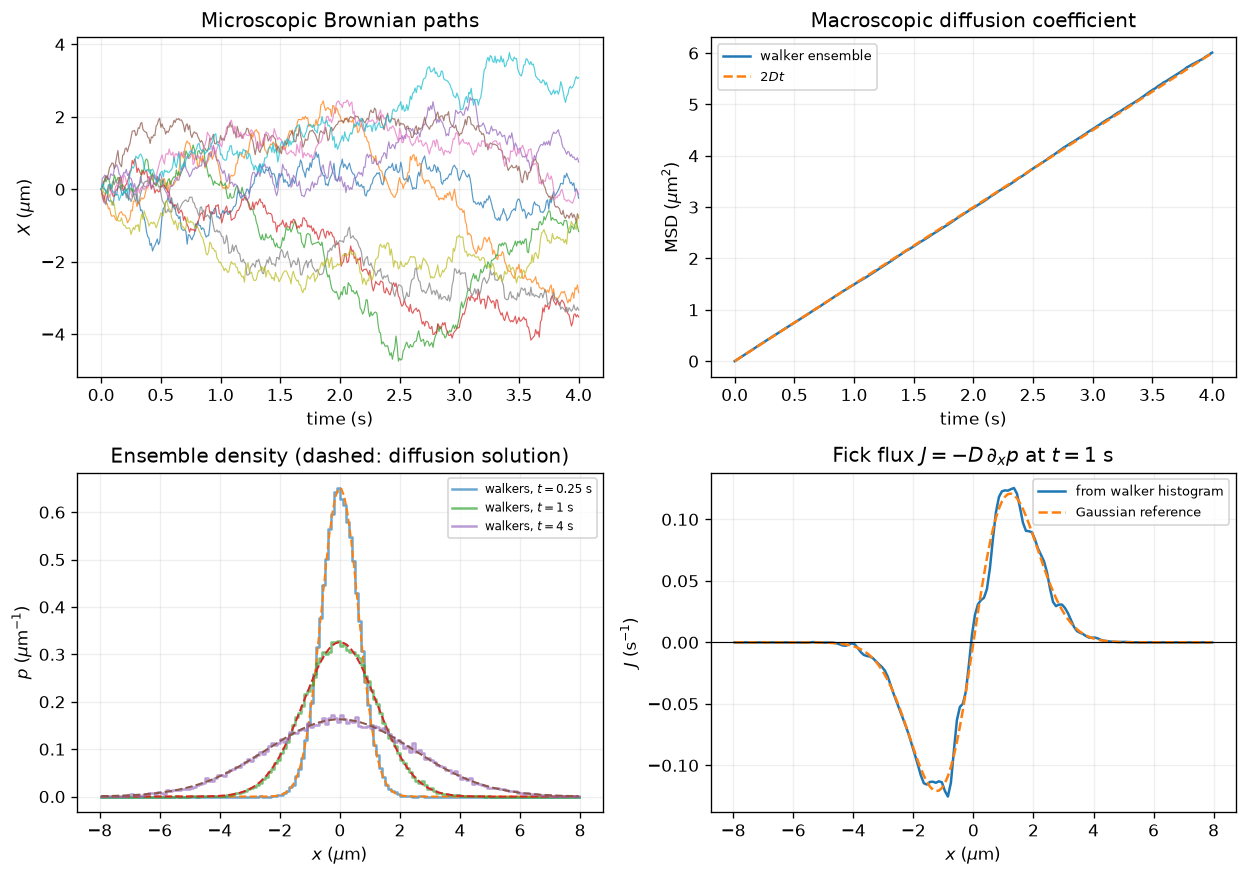

wrote lecture-notes/figures/08_brownian-motion-diffusion/lab-01-brownian-to-ficks-law.pdf


In [6]:
figure, axes = plt.subplots(2, 2, figsize=(10.5, 7.4))

axes[0, 0].plot(time, shown_paths, linewidth=0.7, alpha=0.75)
axes[0, 0].set(title="Microscopic Brownian paths", xlabel="time (s)", ylabel=r"$X$ ($\mu$m)")

axes[0, 1].plot(time, mean_square_displacement, label="walker ensemble")
axes[0, 1].plot(time, 2.0 * diffusivity * time, "--", label=r"$2Dt$")
axes[0, 1].set(title="Macroscopic diffusion coefficient", xlabel="time (s)", ylabel=r"MSD ($\mu$m$^2$)")
axes[0, 1].legend(fontsize=8)

for sample_time in density_times:
    axes[1, 0].step(
        coordinate,
        empirical_density[sample_time],
        where="mid",
        alpha=0.65,
        label=rf"walkers, $t={sample_time:g}$ s",
    )
    axes[1, 0].plot(coordinate, exact_density[sample_time], "--", linewidth=1.2)
axes[1, 0].set(title="Ensemble density (dashed: diffusion solution)", xlabel=r"$x$ ($\mu$m)", ylabel=r"$p$ ($\mu$m$^{-1}$)")
axes[1, 0].legend(fontsize=7)

axes[1, 1].plot(coordinate, measured_fick_flux, label="from walker histogram")
axes[1, 1].plot(coordinate, reference_flux, "--", label="Gaussian reference")
axes[1, 1].axhline(0.0, color="black", linewidth=0.7)
axes[1, 1].set(title=r"Fick flux $J=-D\,\partial_xp$ at $t=1$ s", xlabel=r"$x$ ($\mu$m)", ylabel=r"$J$ (s$^{-1}$)")
axes[1, 1].legend(fontsize=8)

for axis in axes.flat:
    axis.grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "lab-01-brownian-to-ficks-law.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": "DLSU SEMPHY01", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")

## Questions and extensions

1. Double `time_step` without changing $D$. Does the MSD estimate change within
   sampling uncertainty? Why is Brownian motion special in this respect?
2. Reduce `walker_count` by factors of 10. How do histogram and flux noise
   scale with the number of walkers?
3. Explain why $J(0,t)=0$ even though the density is largest at the origin.
4. If every particle carries charge $q$, show that the charge-current density
   is $j=qJ$. What sign does conventional current have for electrons?